# Практическое занятие №2: Градиентный спуск и оптимизаторы
**Цели занятия:**
- Научиться визуализировать функции потерь двух переменных (3D и линии уровня).
- Реализовать простой градиентный спуск (SGD) с помощью PyTorch и проследить траекторию оптимизации.
- Познакомиться с основными оптимизаторами из семейства gradient descent: SGD с моментом, RMSprop, Adam.
- Исследовать влияние скорости обучения (learning rate) на сходимость.

Слова "**Задание**" выделены жирным шрифтом по тексту.

## 1. Импорт необходимых библиотек
Установка и импорт:
- `torch` для автоматического дифференцирования и оптимизаторов.
- `numpy` для численных операций.
- `matplotlib` для построения графиков (3D, контурные, анимация).
- `ipywidgets` (опционально) для интерактивности.

In [28]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation
from IPython.display import HTML
import warnings
warnings.filterwarnings('ignore')

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 2. Функции для визуализации
Определим две классические тестовые функции:
- **Функция Розенброка** (Rosenbrock) — «овражная» функция, сложная для оптимизации:
  $$f(x,y) = (a - x)^2 + b\,(y - x^2)^2,\quad a=1,\; b=100.$$
  Глобальный минимум в точке $(1,1)$.
- **Функция Химмельблау** (Himmelblau) — с несколькими локальными минимумами:
  $$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$
  Четыре локальных минимума: $(3,2)$, $(-2.805,3.131)$, $(-3.779,-3.283)$, $(3.584,-1.848)$.

In [29]:
def rosenbrock(x, y, a=1, b=100):
    return (a - x)**2 + b * (y - x**2)**2

def himmelblau(x, y):
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

# Создадим сетку для построения графиков
x = np.linspace(-2, 2, 100)
y = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x, y)
Z_rosen = rosenbrock(X, Y)

# Для Химмельблау возьмём более широкий диапазон
x_h = np.linspace(-5, 5, 100)
y_h = np.linspace(-5, 5, 100)
X_h, Y_h = np.meshgrid(x_h, y_h)
Z_himm = himmelblau(X_h, Y_h)

### 2.1 3D-визуализация функций
**Задание 1**: построить поверхности функций Розенброка и Химмельблау в 3D с возможностью интерактивного вращения. Обратите внимание на овраг у Розенброка и несколько впадин у Химмельблау.

Пример можно взять из лекции (библиотека plotly).

In [30]:
import plotly.graph_objects as go

go.Figure(data=[go.Surface(z=Z_rosen, x=X, y=Y)]).update_layout(
    title='Функция Розенброка',
    scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x,y)')
).show()

go.Figure(data=[go.Surface(z=Z_himm, x=X_h, y=Y_h)]).update_layout(
    title='Функция Химмельблау',
    scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x,y)')
).show()

### 2.2 Контурные графики (линии уровня)
**Задание 2.** Нарисовать контурные графиках и точки глобальных (или локальных) минимумов на них.
Можно matplotlib или seaborn. (Проявить фантазию в оформлении!)

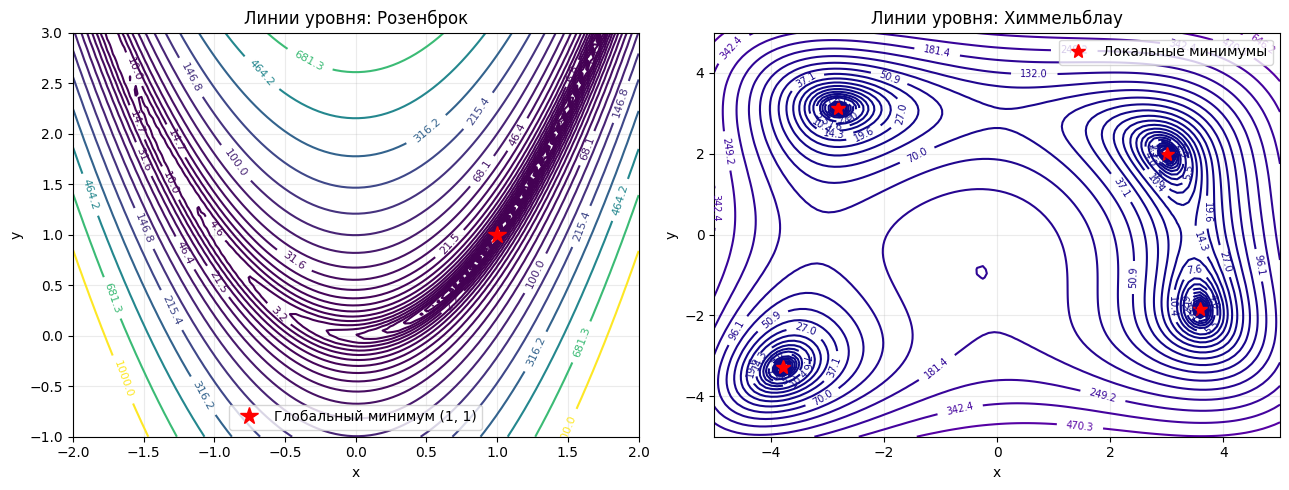

In [31]:
# координаты стационарных точек Химмельблау
minima = [(3.0, 2.0), (-2.805, 3.131), (-3.779, -3.283), (3.584, -1.848)]

panels, (left, right) = plt.subplots(1, 2, figsize=(13, 5))


def style_axes(ax, title):
    ax.set_title(title)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.grid(alpha=0.25)


lev_r = np.logspace(-1, 3, 25)
c_r = left.contour(X, Y, Z_rosen, levels=lev_r, cmap='viridis')
left.clabel(c_r, inline=True, fontsize=8, fmt='%.1f')
left.plot(1, 1, 'r*', markersize=13, label='Глобальный минимум (1, 1)')
style_axes(left, 'Линии уровня: Розенброк')
left.legend()

lev_h = np.logspace(-0.5, 3.5, 30)
c_h = right.contour(X_h, Y_h, Z_himm, levels=lev_h, cmap='plasma')
right.clabel(c_h, inline=True, fontsize=7, fmt='%.1f')
for k, (px, py) in enumerate(minima):
    right.plot(px, py, 'r*', markersize=10,
               label='Локальные минимумы' if k == 0 else None)
style_axes(right, 'Линии уровня: Химмельблау')
right.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Задание 3.** Изучите полученные графики. Почему функция Розенброка считается сложной для градиентного спуска? (Ответьте в ячейке ниже)

*Ваш ответ:*  

Функция Розенброка трудна для градиентного спуска из-за узкого изогнутого "оврага": поперёк него градиент огромен, а вдоль дна почти нулевой. Поэтому метод скачет со стенки на стенку и продвигается к минимуму крайне медленно.

## 3. Реализация градиентного спуска (SGD) с помощью PyTorch

Будем минимизировать функцию двух переменных, используя автоматическое дифференцирование PyTorch. Создадим тензоры с включённым `requires_grad=True` и на каждом шаге будем обновлять их с помощью правила SGD:
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t).$$

В цикле оптимизации необходимо:
1. Вычислить значение функции.
2. Вызвать `.backward()` для вычисления градиентов.
3. Обновить параметры вручную (или с помощью оптимизатора).
4. Обнулить градиенты (`.grad.zero_()`).

Напишем функцию, которая выполняет заданное количество шагов SGD и записывает траекторию.

In [32]:
def sgd_trajectory(func, x0, y0, lr=0.01, steps=50):
    """
    Выполняет SGD для функции func(x,y) от двух переменных.
    Возвращает списки x_hist, y_hist, f_hist.
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        # Вычисляем функцию
        f = func(x, y)
        # Сохраняем историю (отсоединяем от графа вычислений)
        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

        # Градиенты
        f.backward()

        # Обновление вручную (SGD)
        with torch.no_grad():
            x -= lr * x.grad
            y -= lr * y.grad

        # Обнуляем градиенты
        x.grad.zero_()
        y.grad.zero_()

    return x_hist, y_hist, f_hist

Протестируем на функции Розенброка с начальной точкой (-1.5, 1.5), learning rate = 0.001 и 200 шагов. Построим траекторию на контурном графике.

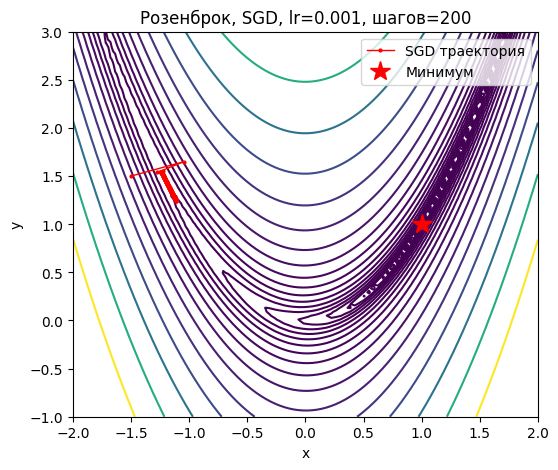

In [33]:
x0, y0 = -1.5, 1.5
lr = 0.001
steps = 200

x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, x0, y0, lr, steps)

# Визуализация
plt.figure(figsize=(6,5))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis')
plt.plot(x_hist, y_hist, 'r.-', markersize=4, linewidth=1, label='SGD траектория')
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Розенброк, SGD, lr={lr}, шагов={steps}')
plt.legend()
plt.show()

**Задание 4.** Поэкспериментируйте с learning rate и начальной точкой. Попробуйте для обеих функций:
- Попробовать 5 различных значений learning rate (например, 0.01, 0.05). Что происходит?
- Попробовать 5 различных начальных точек, например (0, 2) или (-1, -1) или случаным образом выбранных, надётся ли действительный глобальный минимум?

Результирующие графики всех экспериментов сохраните в отчётном блокноте.



In [34]:
# =========================================================
# Эксперимент A: Розенброк — влияние learning rate
# =========================================================
rosen_lrs = [0.0003, 0.001, 0.003, 0.01, 0.03]
rosen_start = (-1.5, 1.5)
rosen_steps = 250

g, cells = plt.subplots(2, 3, figsize=(14, 8))
cells = cells.ravel()
for k, eta in enumerate(rosen_lrs):
    px, py, _ = sgd_trajectory(rosenbrock, *rosen_start, lr=eta, steps=rosen_steps)
    cells[k].contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20),
                     cmap='viridis', alpha=0.55)
    cells[k].plot(px, py, 'r.-', markersize=3, linewidth=1)
    cells[k].plot(1, 1, 'r*', markersize=10)
    cells[k].set(xlim=(-2, 2), ylim=(-1, 3),
                 title=f'Rosenbrock, lr={eta}', xlabel='x', ylabel='y')
cells[-1].axis('off')
plt.tight_layout()
plt.show()


# =========================================================
# Эксперимент B: Розенброк — влияние стартовой точки
# =========================================================
rosen_origins = [(-1.5, 1.5), (-1.0, 1.0), (0.0, 2.0), (-1.0, -1.0), (1.8, 2.5)]
rosen_eta = 0.001

g, cells = plt.subplots(2, 3, figsize=(14, 8))
cells = cells.ravel()
for k, (sx, sy) in enumerate(rosen_origins):
    px, py, _ = sgd_trajectory(rosenbrock, sx, sy, lr=rosen_eta, steps=rosen_steps)
    cells[k].contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20),
                     cmap='viridis', alpha=0.55)
    cells[k].plot(px, py, 'b.-', markersize=3, linewidth=1)
    cells[k].plot(sx, sy, 'ko', markersize=5)
    cells[k].plot(1, 1, 'r*', markersize=10)
    cells[k].set(xlim=(-2, 2), ylim=(-1, 3),
                 title=f'start=({sx}, {sy})', xlabel='x', ylabel='y')
cells[-1].axis('off')
plt.tight_layout()
plt.show()


# =========================================================
# Эксперимент C: Химмельблау — влияние learning rate
# =========================================================
himm_lrs = [0.001, 0.003, 0.005, 0.01, 0.02]
himm_start = (0.0, 0.0)
himm_steps = 220

g, cells = plt.subplots(2, 3, figsize=(14, 8))
cells = cells.ravel()
for k, eta in enumerate(himm_lrs):
    px, py, _ = sgd_trajectory(himmelblau, *himm_start, lr=eta, steps=himm_steps)
    cells[k].contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma', alpha=0.6)
    cells[k].plot(px, py, 'c.-', markersize=3, linewidth=1)
    for m, (mx, my) in enumerate(minima):
        cells[k].plot(mx, my, 'r*', markersize=7,
                      label='Минимумы' if m == 0 else None)
    cells[k].set(xlim=(-5, 5), ylim=(-5, 5),
                 title=f'Himmelblau, lr={eta}', xlabel='x', ylabel='y')
cells[-1].axis('off')
plt.tight_layout()
plt.show()


# =========================================================
# Эксперимент D: Химмельблау — влияние стартовой точки
# =========================================================
himm_origins = [(0.0, 0.0), (-4.0, 4.0), (-4.0, -4.0), (4.0, -4.0), (2.0, 4.0)]
himm_eta = 0.01

g, cells = plt.subplots(2, 3, figsize=(14, 8))
cells = cells.ravel()
for k, (sx, sy) in enumerate(himm_origins):
    px, py, _ = sgd_trajectory(himmelblau, sx, sy, lr=himm_eta, steps=himm_steps)
    dists = [np.hypot(px[-1]-mx, py[-1]-my) for mx, my in minima]
    nearest = minima[np.argmin(dists)]

    cells[k].contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma', alpha=0.6)
    cells[k].plot(px, py, 'm.-', markersize=3, linewidth=1)
    cells[k].plot(sx, sy, 'ko', markersize=5)
    for mx, my in minima:
        cells[k].plot(mx, my, 'r*', markersize=7)
    cells[k].set(xlim=(-5, 5), ylim=(-5, 5),
                 title=f'start=({sx},{sy}) → ({nearest[0]:.2f},{nearest[1]:.2f})',
                 xlabel='x', ylabel='y')
cells[-1].axis('off')
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

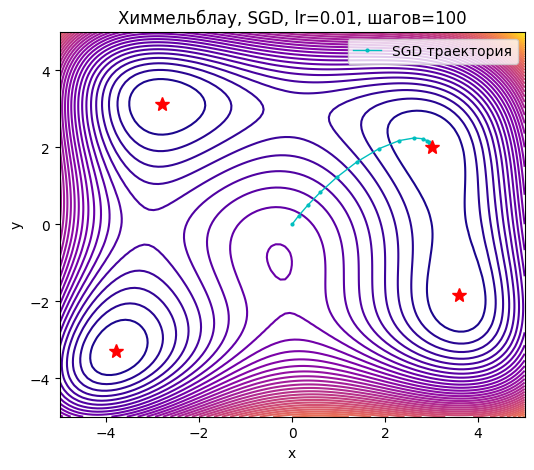

In [35]:
# Ваш эксперимент с Химмельблау
x0_h, y0_h = 0.0, 0.0
lr_h = 0.01
steps_h = 100

x_hist_h, y_hist_h, f_hist_h = sgd_trajectory(himmelblau, x0_h, y0_h, lr_h, steps_h)

plt.figure(figsize=(6,5))
plt.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma')
plt.plot(x_hist_h, y_hist_h, 'c.-', markersize=4, linewidth=1, label='SGD траектория')
# отметим минимумы
for mx, my in minima:
    plt.plot(mx, my, 'r*', markersize=10)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Химмельблау, SGD, lr={lr_h}, шагов={steps_h}')
plt.legend()
plt.show()

## 4. Сравнение оптимизаторов из torch.optim

PyTorch предоставляет готовые реализации многих оптимизаторов: SGD (с momentum и nesterov), RMSprop, Adam и др. Мы можем использовать их, передав параметры модели. В нашем случае модель — это просто два тензора x и y.

Напишем функцию, которая принимает оптимизатор (например, `torch.optim.SGD`), его параметры и возвращает траекторию.

In [36]:
def optimizer_trajectory(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

### 4.1 Сравнение на функции Розенброка
Возьмём начальную точку (-1.5, 1.5), 100 шагов, и сравним:
- SGD (learning rate = 0.001)
- SGD с моментом (lr=0.001, momentum=0.9)
- RMSprop (lr=0.01)
- Adam (lr=0.01)

Построим все траектории на одном контурном графике.

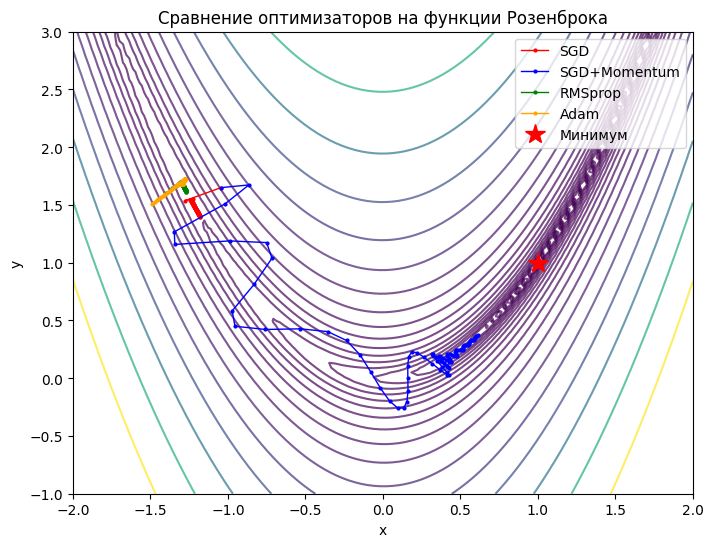

In [37]:
x0, y0 = -1.5, 1.5
steps = 100

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

**Задание 5. Вопросы для анализа:**
- Какой оптимизатор быстрее достиг окрестности минимума?
- Как ведёт себя SGD без момента? Почему он "застревает" в овраге?
- Почему Adam и RMSprop работают лучше?
- Сравнить оптимизаторы по итоговому найденному значению минимизируемой функции.
- Сравнить времена работы (эффективность/производительность) оптимизаторов. Если на одинаковом количестве итераций они оказались примерно одинаковые, попробовать увеличить количество итераций так, чтобы 1-2 метода успели попасть в небольшую окрестность глобального минимума и сравнить методы по количеству этих итераций.


*   Быстрее всех по числу итераций был SGD+Momentum
*   SGD движется медленно и зигзагом вдоль оврага Розенброка - за то же число шагов проходит меньше
*   RMSprop и Adam тоже не так быстры, вероятно, из-за неоптимальных параметров
*   Минимальное финальное значение — у SGD+Momentum, далее RMSprop, SGD, Adam.
*   Время одного шага у методов примерно одинаковое, больше зависит от числа шагов. По соотношению качества и скорости сходимости лучшим оказался SGD+Momentum.


In [38]:
def optimizer_trajectory_1(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)
    eps = 0.05
    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        if abs(x.item()-1)<eps and abs(y.item()-1)<eps:
            print("Количество итераций: "+str(i+1))
            break

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

Количество итераций: 623


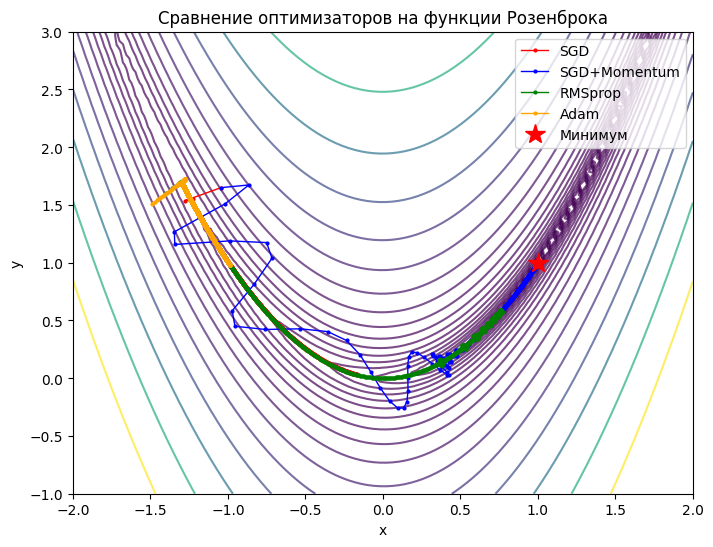

In [39]:
x0, y0 = -1.5, 1.5
steps = 1000

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory_1(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

### 4.2 Анимация траекторий (дополнительно)
Для наглядности можно создать анимацию движения точек. Ниже приведён код для создания GIF-анимации с помощью matplotlib.animation. Запустите эту ячейку, чтобы увидеть, как оптимизаторы "шагают" к минимуму.

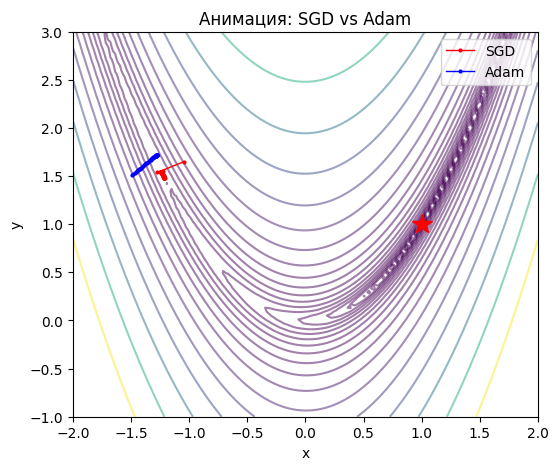

In [40]:
# Создаём анимацию для двух оптимизаторов: SGD и Adam
fig, ax = plt.subplots(figsize=(6,5))
ax.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
ax.plot(1, 1, 'r*', markersize=15)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Анимация: SGD vs Adam')

line_sgd, = ax.plot([], [], 'r.-', lw=1, markersize=4, label='SGD')
line_adam, = ax.plot([], [], 'b.-', lw=1, markersize=4, label='Adam')
ax.legend()

# Получаем траектории (первые steps точек)
steps_anim = 50  # возьмём первые 50 шагов для анимации
x_sgd, y_sgd = trajectories['SGD'][0][:steps_anim], trajectories['SGD'][1][:steps_anim]
x_adam, y_adam = trajectories['Adam'][0][:steps_anim], trajectories['Adam'][1][:steps_anim]

def init():
    line_sgd.set_data([], [])
    line_adam.set_data([], [])
    return line_sgd, line_adam

def animate(i):
    line_sgd.set_data(x_sgd[:i+1], y_sgd[:i+1])
    line_adam.set_data(x_adam[:i+1], y_adam[:i+1])
    return line_sgd, line_adam

anim = animation.FuncAnimation(fig, animate, init_func=init, frames=steps_anim, interval=100, blit=True)

# Для отображения в блокноте:
HTML(anim.to_html5_video())
# Если не работает, можно сохранить в gif: anim.save('comparison.gif', writer='pillow')

## 5. Влияние скорости обучения (learning rate) на сходимость

Проведём эксперимент: зафиксируем начальную точку (-1.5, 1.5) и оптимизатор SGD (без момента). Будем менять learning rate: очень маленький (0.0001), средний (0.001), большой (0.01) и слишком большой (0.1). Наблюдаем поведение.

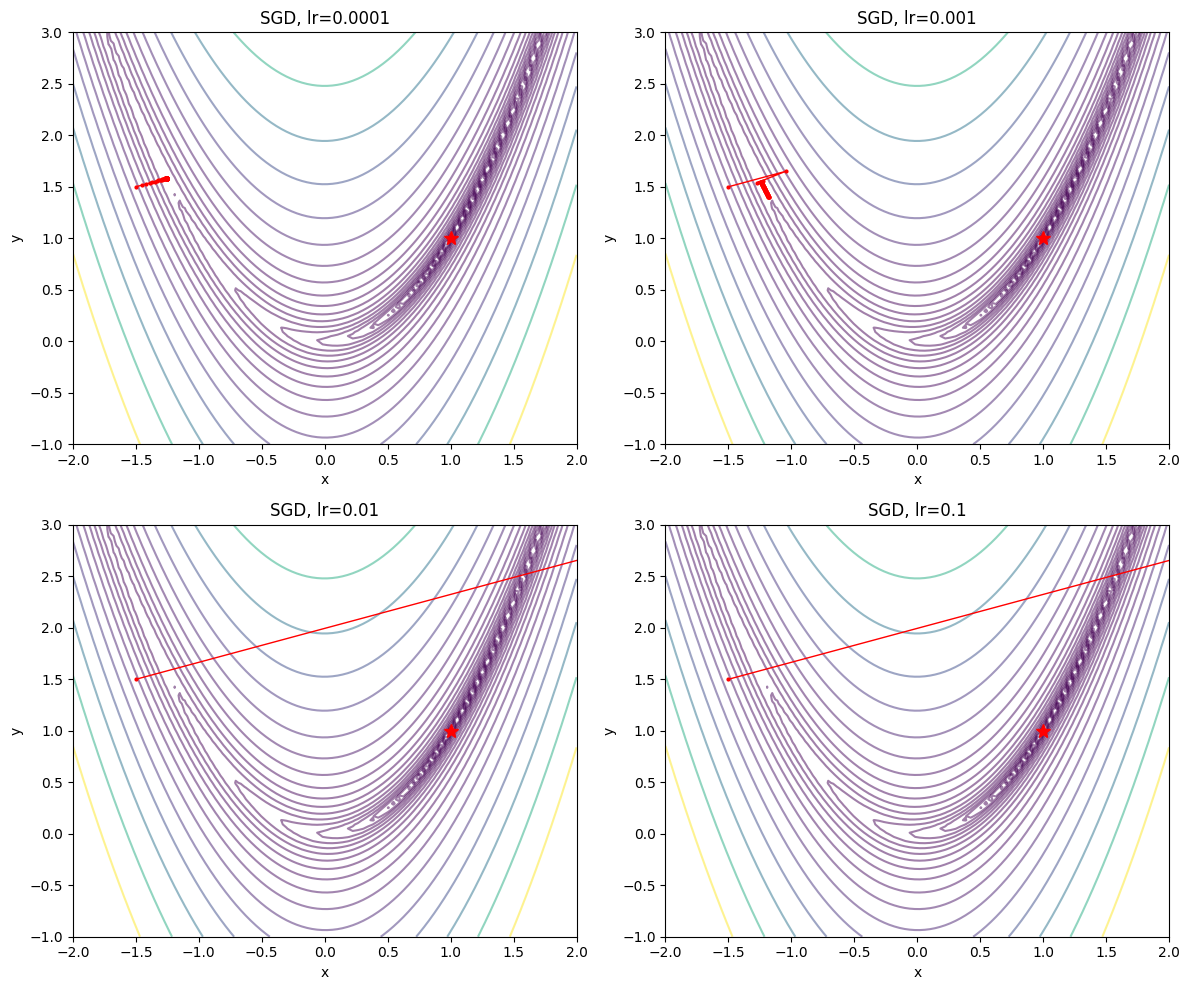

In [41]:
lrs_to_try = [0.0001, 0.001, 0.01, 0.1]
x0, y0 = -1.5, 1.5
steps = 100

plt.figure(figsize=(12,10))

for i, lr in enumerate(lrs_to_try):
    xh, yh, fh = sgd_trajectory(rosenbrock, x0, y0, lr, steps)
    plt.subplot(2,2,i+1)
    plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
    plt.plot(xh, yh, 'r.-', markersize=4, linewidth=1)
    plt.plot(1, 1, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'SGD, lr={lr}')
    plt.xlim(-2,2)
    plt.ylim(-1,3)

plt.tight_layout()
plt.show()

**Обсуждение:**
- При очень маленьком LR (0.0001) алгоритм не успевает дойти до минимума за 100 шагов.
- При LR=0.001 траектория медленно сползает в овраг и движется к минимуму.
- При LR=0.01 шаги больше, но из-за оврага траектория может "перепрыгивать" и колебаться.
- При LR=0.1 градиентный спуск расходится: шаги становятся настолько большими, что точка улетает за пределы графика. Это иллюстрация "взрыва градиентов" (хотя здесь не градиенты взрываются, а слишком большой шаг).

**Задание 6.** Для функции Химмельблау и начальной точки (0, 0) подберите такое значение learning rate для SGD, чтобы алгоритм сошёлся к одному из минимумов, но при этом траектория была "интересной" (например, с колебаниями). Попробуйте также очень большое LR и посмотрите, куда улетает точка.

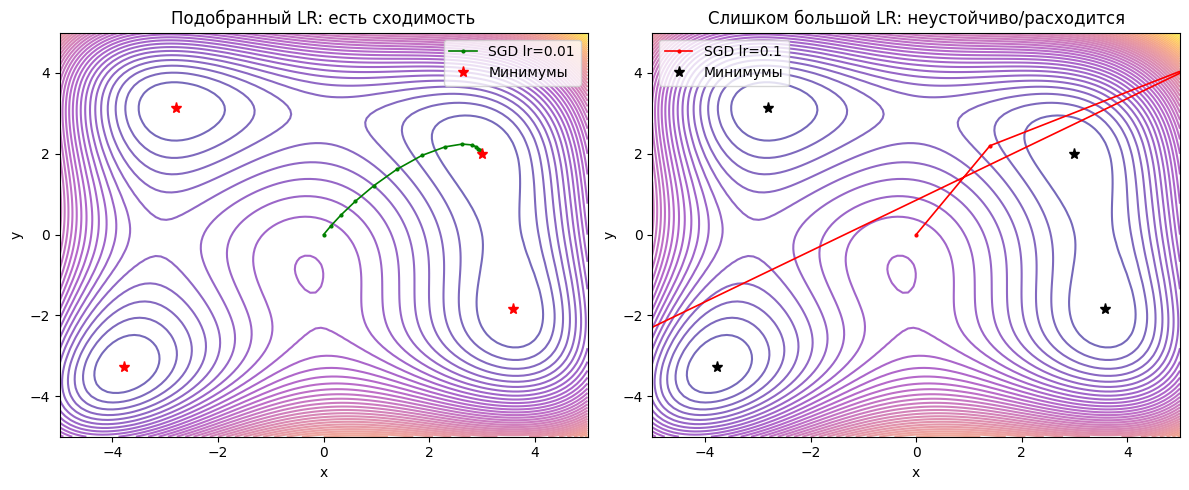

lr=0.01: финал (3.000, 2.000), ближайший минимум (3.000, 2.000), расстояние=0.0000
lr=0.1: расходится=True, сохранено шагов=4


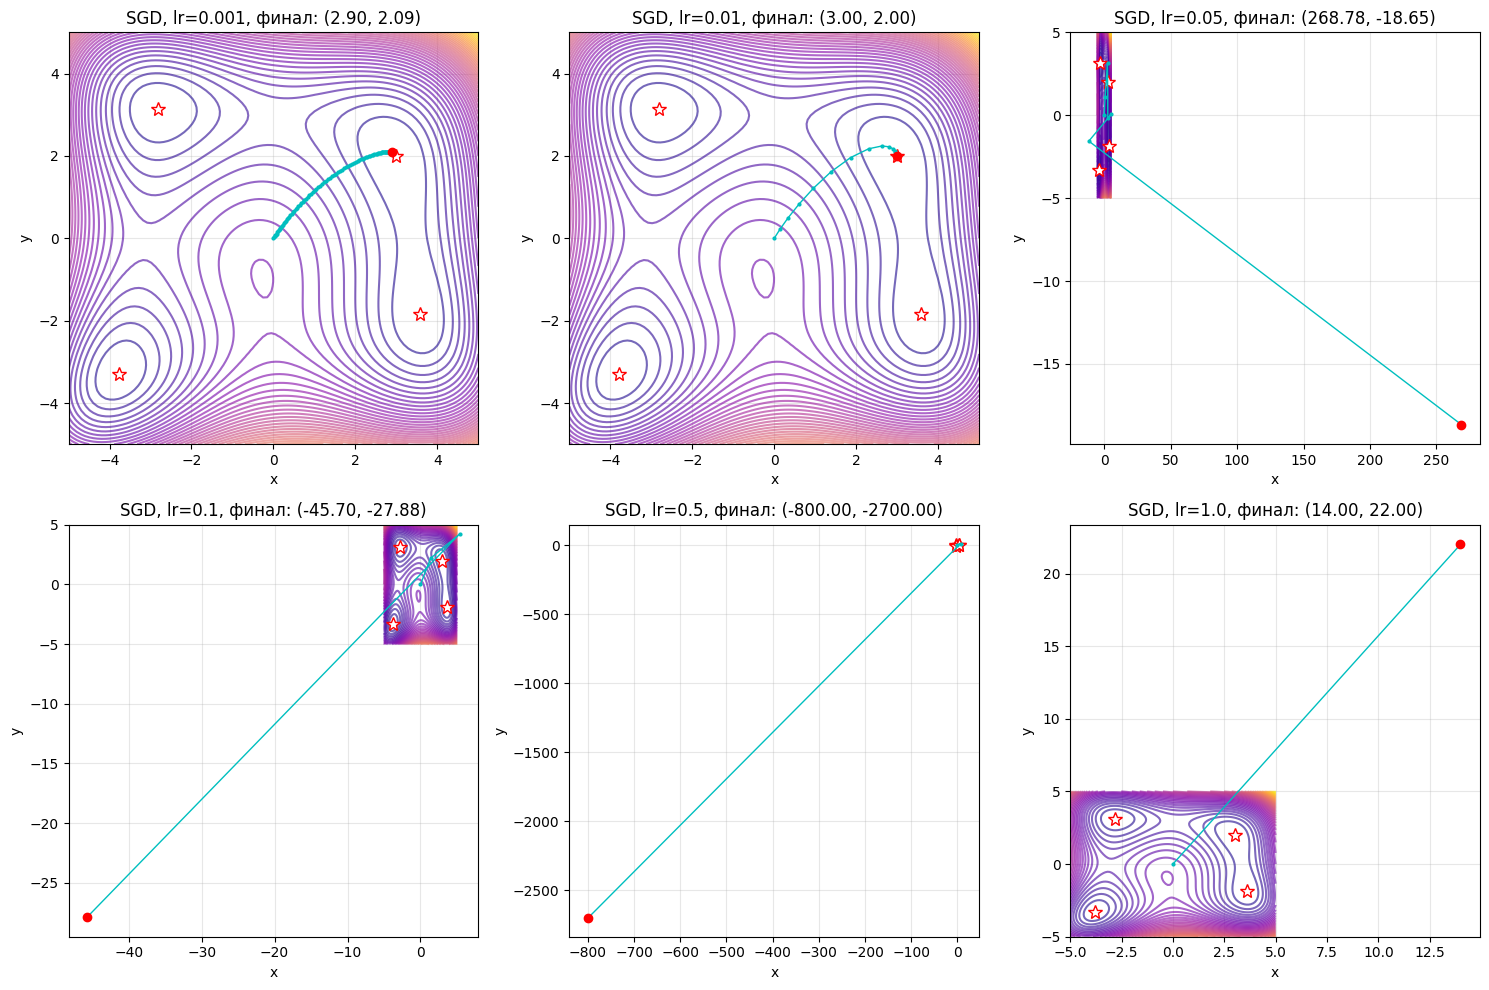

ИТОГИ СВИПА ПО LEARNING RATE
lr=0.001: финал (2.904, 2.095), loss=0.309
lr=0.01: финал (3.000, 2.000), loss=0.000
lr=0.05: финал (268.779, -18.655), loss=5215015936.000
lr=0.1: финал (-45.695, -27.884), loss=4724408.000
lr=0.5: финал (-800.000, -2700.000), loss=53538474426368.000
lr=1.0: финал (14.000, 22.000), loss=283930.000


In [43]:
# Ваш эксперимент с Химмельблау и разными LR
# =========================================================
# Химмельблау: как learning rate влияет на сходимость SGD
# =========================================================

def run_sgd(func, x_start, y_start, eta=0.01, max_steps=100):
    """SGD-траектория с защитой от расхождения и NaN."""
    vx = torch.tensor(x_start, requires_grad=True, dtype=torch.float32)
    vy = torch.tensor(y_start, requires_grad=True, dtype=torch.float32)

    trail_x, trail_y, trail_f = [], [], []
    blew_up = False

    for _ in range(max_steps):
        loss = func(vx, vy)

        if not torch.isfinite(loss):
            blew_up = True
            break

        trail_x.append(vx.item())
        trail_y.append(vy.item())
        trail_f.append(loss.item())

        loss.backward()
        with torch.no_grad():
            vx -= eta * vx.grad
            vy -= eta * vy.grad

        if abs(vx.item()) > 1e4 or abs(vy.item()) > 1e4:
            blew_up = True
            break

        vx.grad.zero_()
        vy.grad.zero_()

    return trail_x, trail_y, trail_f, blew_up


# ---------- Часть 1: «хороший» vs «плохой» lr ----------
x_start, y_start = 0.0, 0.0
max_steps = 120
eta_small, eta_large = 0.01, 0.1

g, (p_ok, p_fail) = plt.subplots(1, 2, figsize=(12, 5))


def draw_panel(ax, xs, ys, eta, caption, color, star):
    ax.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma', alpha=0.6)
    ax.plot(xs, ys, color=color, linestyle='-', marker='.',
            markersize=4, linewidth=1.2, label=f'SGD lr={eta}')
    for i, (mx, my) in enumerate(minima):
        ax.plot(mx, my, star, markersize=8,
                label='Минимумы' if i == 0 else None)
    ax.set(xlim=(-5, 5), ylim=(-5, 5), xlabel='x', ylabel='y', title=caption)
    ax.legend()


xs_ok, ys_ok, _, _ = run_sgd(himmelblau, x_start, y_start, eta_small, max_steps)
draw_panel(p_ok, xs_ok, ys_ok, eta_small,
           'Подобранный LR: есть сходимость', 'green', 'r*')

xs_bad, ys_bad, _, diverged = run_sgd(himmelblau, x_start, y_start, eta_large, max_steps)
draw_panel(p_fail, xs_bad, ys_bad, eta_large,
           'Слишком большой LR: неустойчиво/расходится', 'red', 'k*')

plt.tight_layout()
plt.show()

if xs_ok:
    dists = [np.hypot(xs_ok[-1] - mx, ys_ok[-1] - my) for mx, my in minima]
    k = int(np.argmin(dists))
    bx, by = minima[k]
    print(f'lr={eta_small}: финал ({xs_ok[-1]:.3f}, {ys_ok[-1]:.3f}), '
          f'ближайший минимум ({bx:.3f}, {by:.3f}), расстояние={dists[k]:.4f}')
print(f'lr={eta_large}: расходится={diverged}, сохранено шагов={len(xs_bad)}')


# ---------- Часть 2: свип по learning rate ----------
lr_grid = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
x_start, y_start = 0.0, 0.0
max_steps = 100

plt.figure(figsize=(15, 10))
for k, eta in enumerate(lr_grid):
    xs, ys, fs, _ = run_sgd(himmelblau, x_start, y_start, eta, max_steps)

    panel = plt.subplot(2, 3, k + 1)
    panel.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma', alpha=0.6)
    for mx, my in minima:
        panel.plot(mx, my, 'w*', markersize=10,
                   markeredgecolor='red', markeredgewidth=1)
    panel.plot(xs, ys, 'c.-', markersize=4, linewidth=1)
    panel.plot(xs[-1], ys[-1], 'ro', markersize=6)
    panel.set(xlabel='x', ylabel='y',
              title=f'SGD, lr={eta}, финал: ({xs[-1]:.2f}, {ys[-1]:.2f})')
    panel.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------- Сводка по свипу ----------
print('ИТОГИ СВИПА ПО LEARNING RATE')
for eta in lr_grid:
    xs, ys, fs, _ = run_sgd(himmelblau, x_start, y_start, eta, max_steps)
    print(f'lr={eta}: финал ({xs[-1]:.3f}, {ys[-1]:.3f}), loss={fs[-1]:.3f}')

## **6. Итоги занятия**

* Что нового узнали? (навыки/умения/знания).
* Что добавить/убрать/расписать подробнее/усложнить/упростить и т.д.


На практике освоили визуализацию ландшафтов функций потерь (3D-поверхности и линии уровня), ручной запуск SGD и сравнение оптимизаторов по траектории, скорости и качеству сходимости.

На овражной функции Розенброка обычный SGD сильно зависит от шага и часто продвигается медленно, тогда как Adam, RMSprop и SGD с моментом сходятся устойчивее и быстрее. Learning rate критичен: слишком маленький замедляет обучение, слишком большой ведёт к колебаниям или расходимости.